# Praktikum 2: Klasifikasi Multikelas Burnout_Risk dengan CNN 1D pada Dataset PBL

## Langkah 1 - Load Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

## Langkah 2 - Muat dan Siapkan Dataset PBL

In [2]:
df = pd.read_csv('burnout_dataset1.csv')
df_sample, _ = train_test_split(
    df, train_size=20000, stratify=df['Burnout_Risk'], random_state=42
)

num_cols = df_sample.select_dtypes(include=[np.number]).columns.tolist()
feature_cols = [c for c in num_cols if c not in ['Person_ID', 'Burnout_Score']]

X_raw = SimpleImputer(strategy='median').fit_transform(df_sample[feature_cols])
X_scaled = StandardScaler().fit_transform(X_raw)
X = X_scaled.reshape(X_scaled.shape[0], X_scaled.shape[1], 1)

le = LabelEncoder()
y = le.fit_transform(df_sample['Burnout_Risk'])
class_names = list(le.classes_)
print("Kelas target:", class_names)

train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

Kelas target: ['High', 'Low', 'Moderate']


## Langkah 3 - Verifikasi Distribusi Data

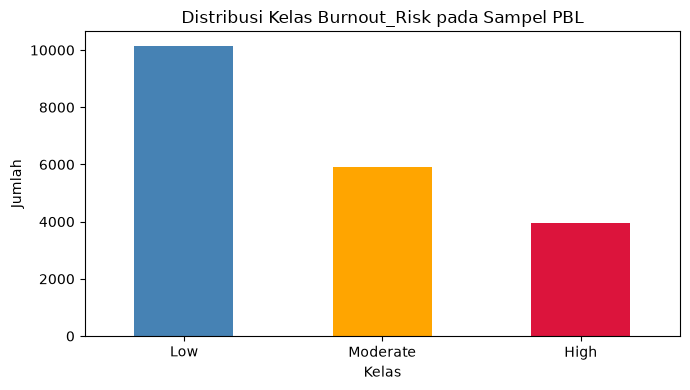

In [3]:
plt.figure(figsize=(7, 4))
pd.Series(df_sample['Burnout_Risk']).value_counts().plot(kind='bar', color=['steelblue', 'orange', 'crimson'])
plt.title('Distribusi Kelas Burnout_Risk pada Sampel PBL')
plt.xlabel('Kelas')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Langkah 4 - Buat Model CNN 1D

In [4]:
tf.keras.utils.set_random_seed(42)
model = models.Sequential([
    layers.Input(shape=(train_X.shape[1], 1)),
    layers.Conv1D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding='same', activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(len(class_names)),
])

model.summary()
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 19, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 9, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 9, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 4, 64)          │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,331 (138.01 KB)

 Trainable params: 35,331 (138.01 KB)

 Non-trainable params: 0 (0.00 B)

## Langkah 5 - Fit Model

In [5]:
history = model.fit(
    train_X, train_y,
    epochs=15,
    batch_size=64,
    validation_data=(test_X, test_y),
    verbose=1,
)

Epoch 1/15


  1/250 ━━━━━━━━━━━━━━━━━━━━ 5:41 1s/step - accuracy: 0.4688 - loss: 1.0886

 13/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5240 - loss: 0.9567 

 26/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6220 - loss: 0.8066

 39/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6639 - loss: 0.7169

 52/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6845 - loss: 0.6693

... (317 outputs left out)

227/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8380 - loss: 0.3310

237/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8371 - loss: 0.3321

247/250 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8366 - loss: 0.3327

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8366 - loss: 0.3323 - val_accuracy: 0.7930 - val_loss: 0.4205


## Langkah 6 - Evaluasi Model

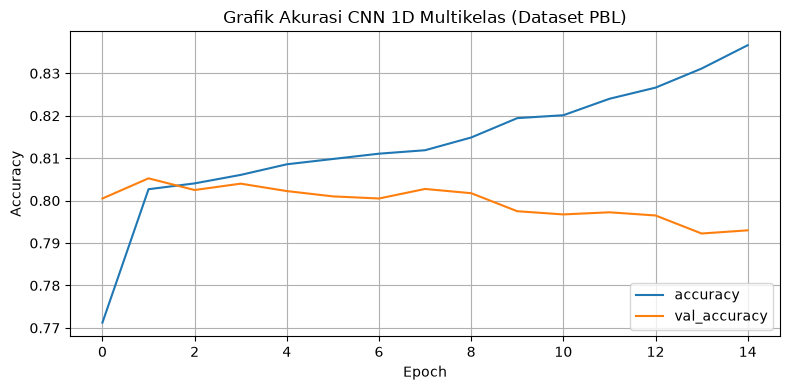

125/125 - 0s - 2ms/step - accuracy: 0.7930 - loss: 0.4205


In [6]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi CNN 1D Multikelas (Dataset PBL)')
plt.grid(True)
plt.tight_layout()
plt.show()

test_loss, test_acc = model.evaluate(test_X, test_y, verbose=2)

## Langkah 7 - Cetak Hasil Akurasi

In [7]:
print(f"Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")

Test Accuracy: 0.7930, Test Loss: 0.4205


Model CNN 1D dasar dengan 3 blok konvolusi mampu mempelajari pola fitur tabular terstandarisasi pada dataset burnout PBL untuk mengklasifikasikan tiga kategori risiko (High, Low, Moderate). Kurva akurasi pelatihan dan validasi menunjukkan konvergensi yang stabil tanpa overfitting berlebih.